# 01 — Deterministic model: nine bearers

How long does a bearer resist before becoming a wraith? This notebook solves the corruption ODE

$$\frac{dC}{dt} = \alpha\,u(t)\,A\,(1 + \beta C) - \gamma\,W\,(1 - C)$$

for nine bearers with different will $W$, ambition $A$ and initial corruption $C_0$, then shows how a small change in character changes a bearer's fate.

All parameter values are invented assumptions (see the README).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from corruption.model import (
    BearerParams,
    analytic_fall_time,
    critical_ambition,
    fate,
    simulate,
    unstable_fixed_point,
)
from corruption.plotting import plot_trajectories

FIGURES = Path("../docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

## The Nine

Each bearer wears the ring constantly ($u = 1$). Weaker will and bigger ambition mean a faster fall. $C_0$ stands for the bearer's intent when they received the ring.

In [2]:
NINE = [
    (0.30, 0.95, 0.15),
    (0.40, 0.90, 0.10),
    (0.50, 0.85, 0.08),
    (0.55, 0.80, 0.06),
    (0.60, 0.78, 0.05),
    (0.66, 0.78, 0.04),
    (0.72, 0.80, 0.03),
    (0.76, 0.80, 0.02),
    (0.79, 0.80, 0.01),
]
bearers = [BearerParams(W=w, A=a, c0=c0) for w, a, c0 in NINE]
labels = [f"Bearer {i}" for i in range(1, 10)]
trajectories = [simulate(p, t_max=80.0) for p in bearers]

table = pd.DataFrame(
    {
        "W": [p.W for p in bearers],
        "A": [p.A for p in bearers],
        "C0": [p.c0 for p in bearers],
        "A_c": [critical_ambition(p) for p in bearers],
        "C_u": [unstable_fixed_point(p) for p in bearers],
        "fall (numeric)": [t.fall_time for t in trajectories],
        "fall (closed form)": [analytic_fall_time(p) for p in bearers],
    },
    index=labels,
).round(3)
table

,W,A,C0,A_c,C_u,fall (numeric),fall (closed form)
Bearer 1,0.30,0.95,0.15,0.30,-0.206,17.983,17.983
Bearer 2,0.40,0.90,0.10,0.40,-0.161,22.607,22.607
Bearer 3,0.50,0.85,0.08,0.50,-0.115,27.060,27.060
Bearer 4,0.55,0.80,0.06,0.55,-0.085,32.498,32.498
Bearer 5,0.60,0.78,0.05,0.60,-0.061,36.678,36.678
Bearer 6,0.66,0.78,0.04,0.66,-0.040,41.064,41.064
Bearer 7,0.72,0.80,0.03,0.72,-0.026,45.057,45.057
Bearer 8,0.76,0.80,0.02,0.76,-0.013,52.694,52.694
Bearer 9,0.79,0.80,0.01,0.79,-0.003,66.310,66.310


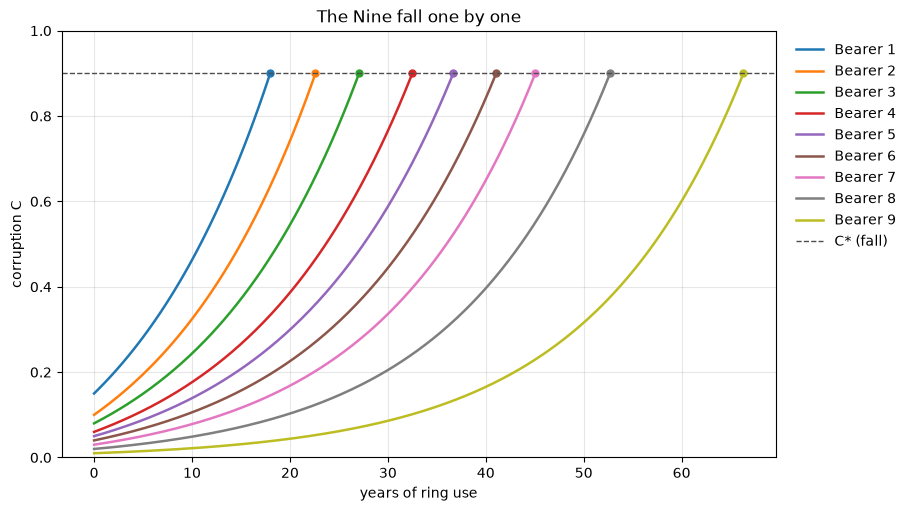

In [3]:
fig = plot_trajectories(
    trajectories, labels, c_star=bearers[0].c_star, title="The Nine fall one by one"
)
fig.savefig(FIGURES / "nine_bearers.png", dpi=150)
plt.show()

Every bearer has $A > A_c = \gamma W / (\alpha u)$, so the point of no return $C_u$ is below zero: none of them can resist under constant use. The numeric fall time from `solve_ivp` matches the closed form

$$t_{fall} = \frac{1}{a}\ln\frac{C^* - C_u}{C_0 - C_u},\qquad a = \alpha u A \beta + \gamma W.$$

## A small change, a different fate

Bearer 9 sits just above the critical ambition. A little more will (W = 0.82) only delays the fall. A little more again (W = 0.84) moves the point of no return above $C_0$: corruption now drains away instead of growing.

Bearer 9 (W = 0.79)    C_u = -0.003  fate: falls
W = 0.82               C_u = +0.006  fate: falls
W = 0.84               C_u = +0.012  fate: resists


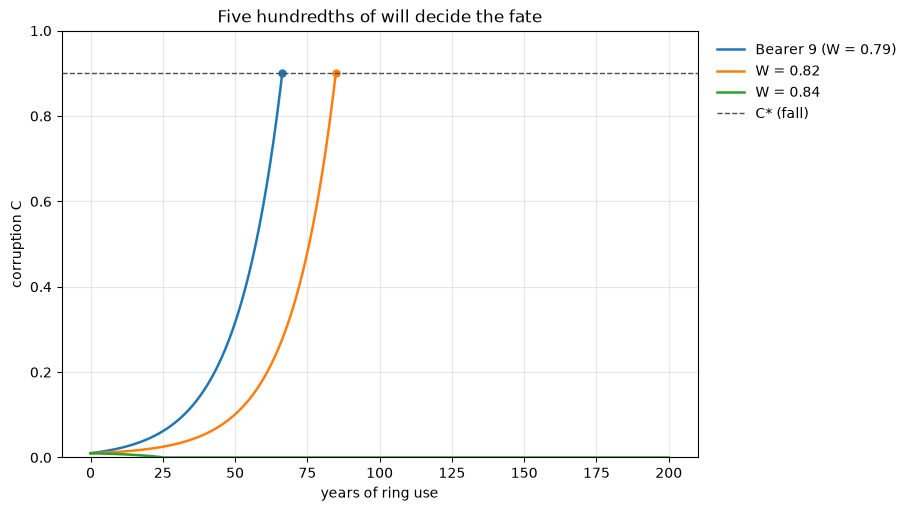

In [4]:
last = bearers[-1]
what_ifs = {
    "Bearer 9 (W = 0.79)": last,
    "W = 0.82": BearerParams(W=0.82, A=last.A, c0=last.c0),
    "W = 0.84": BearerParams(W=0.84, A=last.A, c0=last.c0),
}
for name, p in what_ifs.items():
    print(f"{name:22s} C_u = {unstable_fixed_point(p):+.3f}  fate: {fate(p).value}")

fig = plot_trajectories(
    [simulate(p, t_max=200.0) for p in what_ifs.values()],
    list(what_ifs),
    c_star=last.c_star,
    title="Five hundredths of will decide the fate",
)
fig.savefig(FIGURES / "small_change.png", dpi=150)
plt.show()

## Intermittent use

Usage does not have to be constant. Wearing the ring half of the time (five years on, five years off) delays the fall but does not prevent it for bearer 1.

constant use: falls at 18.0 years
pulsed use:   falls at 34.3 years


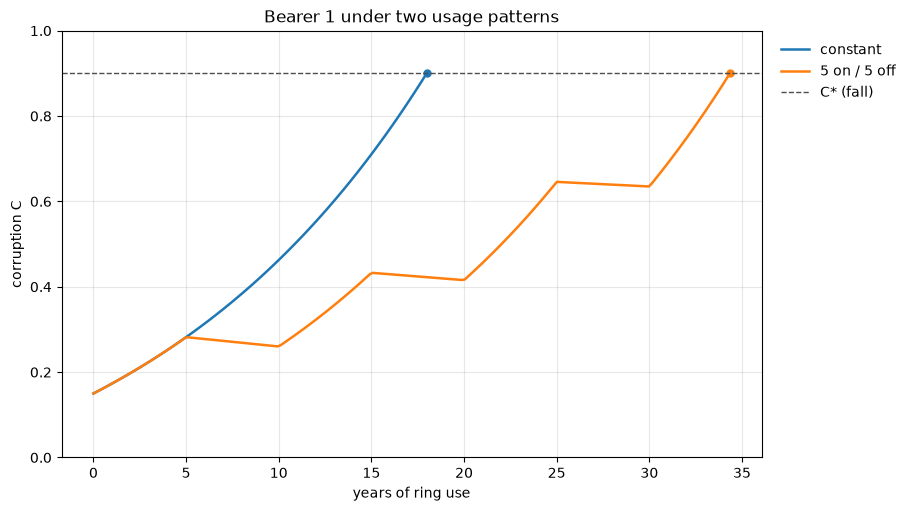

In [5]:
def pulsed(t: float) -> float:
    return 1.0 if (t % 10.0) < 5.0 else 0.0


steady = simulate(bearers[0], t_max=80.0)
intermittent = simulate(bearers[0], t_max=80.0, usage=pulsed, max_step=0.25)
print(f"constant use: falls at {steady.fall_time:.1f} years")
print(f"pulsed use:   falls at {intermittent.fall_time:.1f} years")
fig = plot_trajectories(
    [steady, intermittent],
    ["constant", "5 on / 5 off"],
    c_star=bearers[0].c_star,
    title="Bearer 1 under two usage patterns",
)
plt.show()